# Quantum Programming
## Notebook #1. Discovering Qiskit and manipulating classical circuits

## 0. Building classical circuits with a quantum circuit

Quantum circuits are expressive enough to implement any classical reversible computation (they include gates such as the Toffoli gate, also called **CCX** or **controlled-controlled-NOT**). They can also apply a transformation to a superposition of values.

As seen in the lecture, every classical Boolean circuit can be reproduced by a reversible Boolean circuit, possibly by introducing some work bits (ancilla qubits). These work bits are initialised to 0. At the output of the circuit, we recover the input together with the output. In all cases, we can reset the extra work bits back to 0.

In this exercise sheet, you will build circuits that implement classical Boolean functions with Qiskit. We provide a validator function. This validator runs a simulation on all possible inputs, with the given number of input bits, and at the output it maps qubit measurements to classical bits.

In your circuits, restrict yourself to the gates **X** (NOT on a single qubit), **CX** (controlled-NOT), and **CCX** (controlled-controlled-NOT).


In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit.providers.basic_provider import BasicProvider
from qiskit.visualization import plot_histogram
from qiskit.quantum_info import Operator

# Un simulateur de circuit complet
sim = BasicProvider().get_backend('basic_simulator')

# Afficher un circuit
def draw_circ(circ): display(circ.draw(output='mpl'))
    
def show(circ):
    draw_circ(circ)
    display(Operator(circ).draw('latex'))

A circuit is created by instantiating the class `QuantumCircuit` with the desired number of qubits. You then string the gates onto the circuit's qubits. At any time, it is possible to visualise the circuit with the `draw` method.


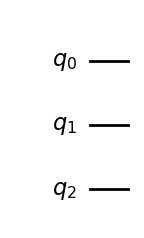

In [7]:
mycirc = QuantumCircuit(3)
mycirc.draw(output='mpl')


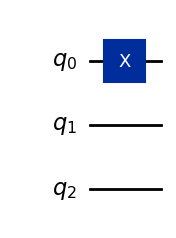

In [8]:
mycirc.x(0) # add a NOT gate on qubit q0
mycirc.draw(output='mpl')  


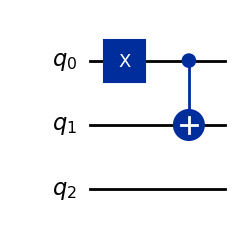

In [9]:
mycirc.cx(0,1) # adds a controlled-NOT gate on qubits q0 (control) and q1 (NOT)
mycirc.draw(output='mpl')


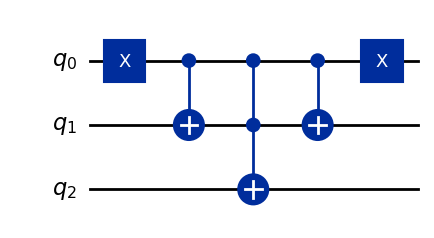

In [10]:
mycirc.ccx(0,1,2)
# and now we reset qubits 0 and 1 to their initial values
mycirc.cx(0,1)
mycirc.x(0)
mycirc.draw(output='mpl')


Here is the code of our validator. You do not need to understand how it works in order to use it in the exercises below.


In [11]:
def validator(ninput, circuit, outset):
    """Tests the classical function computed by the circuit [circuit]
       considering that the first [ninput] qubits receive a
       binary input and that the other qubits are initialised to 0 at input.
       Checks that the set of measures of output qubits produces the set
       of values [outset]."""
    assert circuit.num_clbits == 0
    n = circuit.num_qubits
    nanc = n-ninput
    assert nanc >= 0
    head = QuantumCircuit(n, n)
    for i in range(ninput):
        head.h(i)
    head.barrier()
    tail = QuantumCircuit(n, n)
    tail.barrier()
    for i in range(n):
        tail.measure(i, n-1-i)
    full = head.compose(circuit).compose(tail)
    display(full.draw(output='mpl'))
    res = sim.run(full, shots=65536).result()
    counts = res.get_counts(full)
    display(plot_histogram(counts))
    expset = set(counts.keys())
    return outset == expset

def classicset(ninput, nanc, f):
    rset = set()
    fs = '{:0' + str(ninput) + 'b}'
    ss = '0' * nanc
    for i in range(pow(2,ninput)):
        s = fs.format(i) + ss
        res = f(*map(int,s))
        rset.add(''.join(map(str,res)))
    return rset


The validator is applied to a circuit by indicating the number of input bits and the expected outputs for all values. The validator displays the circuit it executes, the simulation results, and returns `True` or `False` depending on whether the proposed circuit passes the test.

For our example circuit,

| q0 in | q1 in | q0 out | q1 out | q2 out |
|:-:|:-:|:-:|:-:|:-:|
|0|0|0|0|1|
|0|1|0|1|0|
|1|0|1|0|0|
|1|1|1|1|0|


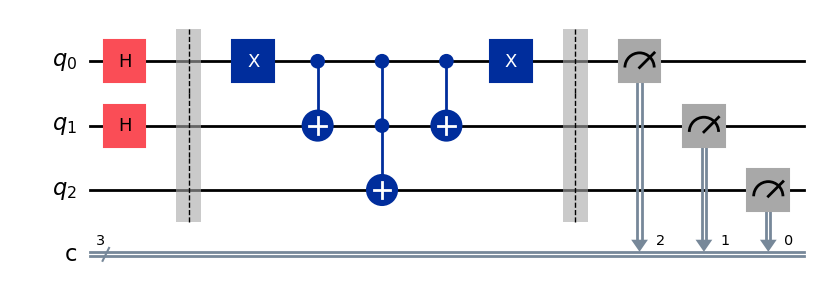

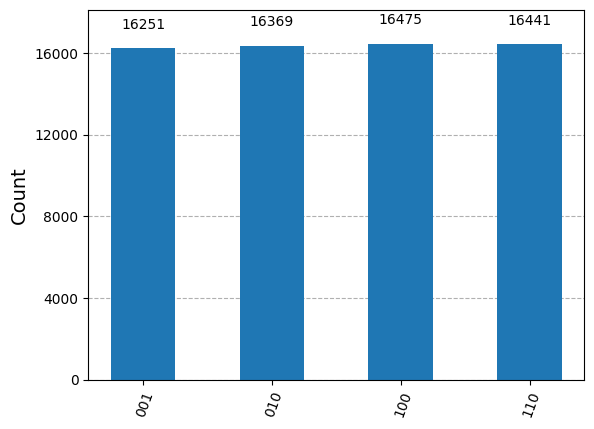

True

In [12]:
validator(2, mycirc, classicset(2, 1, lambda x,y,z: (x,y,(1-x)*(1-y))))


## 1. Classical logic gates


### NOT gate


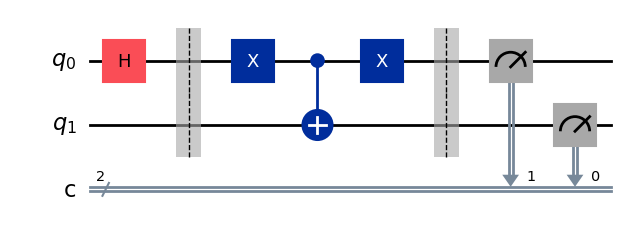

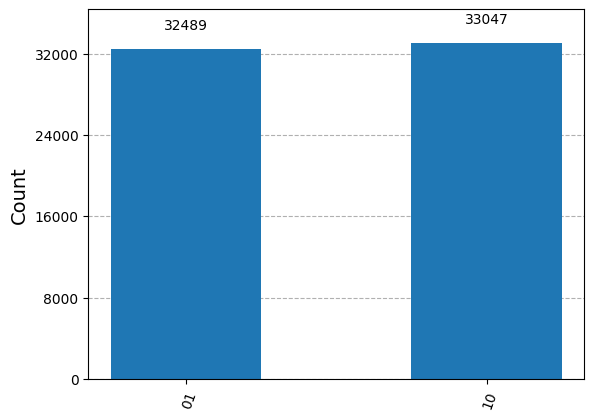

True

In [13]:
circuitNON = QuantumCircuit(2) # one input bit, one output bit

### ADD HERE WHAT IS NEEDED TO MODIFY THE CIRCUIT
### Since it's the first one, here is a proposed solution ;-)
### It's not the best; you can do it with one fewer gate

circuitNON.x(0)
circuitNON.cx(0,1)
circuitNON.x(0)

### AND HERE IS THE TEST THAT MUST RETURN TRUE
validator(1, circuitNON, classicset(1,1, lambda x,y: (x,1-x)))


### AND gate


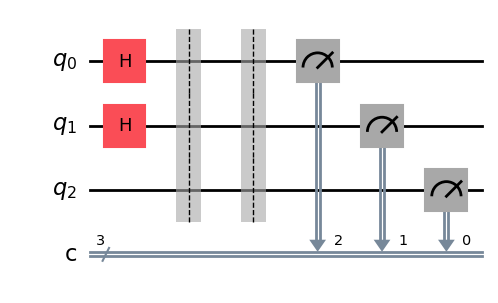

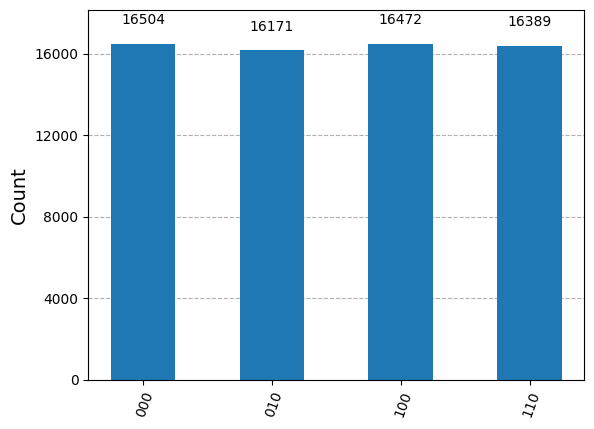

False

In [14]:
circuitET = QuantumCircuit(3) # two input bits, one output bit

### ADD HERE WHAT IS NEEDED TO MODIFY THE CIRCUIT


### AND HERE IS THE TEST THAT MUST RETURN TRUE
validator(2, circuitET, classicset(2,1, lambda x,y,z: (x,y,x*y)))


### OR gate


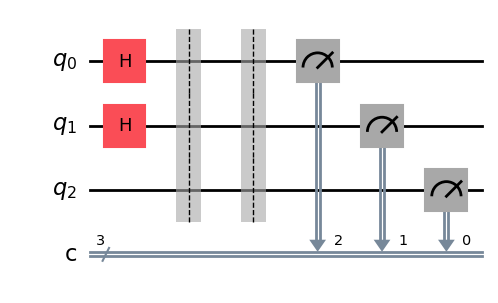

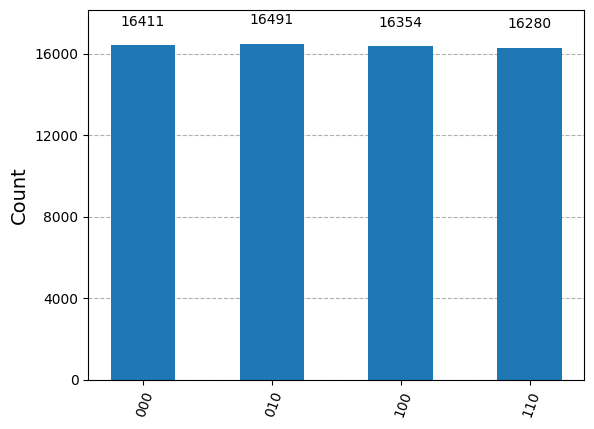

False

In [15]:
circuitOU = QuantumCircuit(3) # two input bits, one output bit

### ADD HERE WHAT IS NEEDED TO MODIFY THE CIRCUIT



### AND HERE IS THE TEST THAT MUST RETURN TRUE
validator(2, circuitOU, classicset(2,1, lambda x,y,z: (x,y,max(x,y))))


### XOR gate


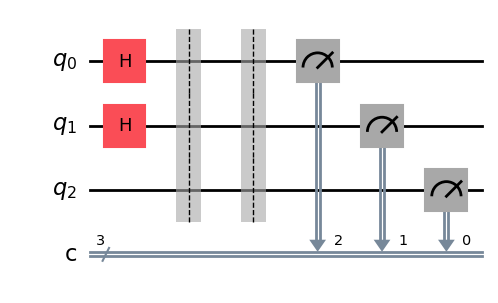

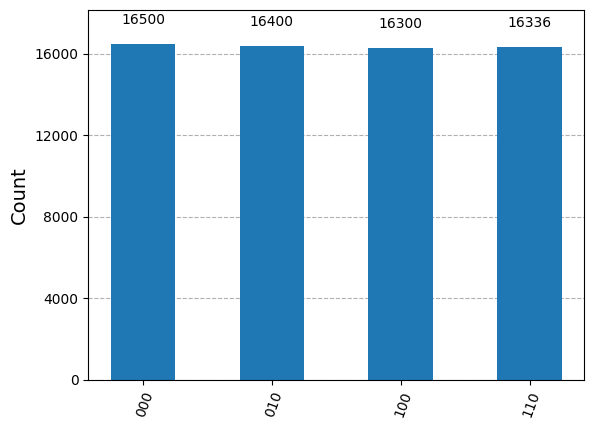

False

In [16]:
circuitXOR = QuantumCircuit(3) # two input bits, one output bit

### ADD HERE WHAT IS NEEDED TO MODIFY THE CIRCUIT


### AND HERE IS THE TEST THAT MUST RETURN TRUE
validator(2, circuitXOR, classicset(2,1, lambda x,y,z: (x,y,x^y)))


## 2. Boolean inner product

For the Bernstein–Vazirani algorithm studied in the lecture, we need a circuit that computes the inner product between an input sequence of $k$ bits $x_1, x_2, \ldots, x_k$ and a fixed constant string $s_1, s_2, \ldots, s_k$. The expected circuit takes as input the bits $x_1, x_2, \ldots, x_k, y$ and returns $x_1, x_2, \ldots, x_k, z$ with
$$
z = y\oplus\left( x_1\cdot s_1 \oplus x_2\cdot s_2 \oplus \cdots \oplus x_k\cdot s_k\right).
$$

For example, on 3 bits:
- if $(s_1,s_2,s_3) = (1,0,1)$ then $z = y \oplus x_1 \oplus x_3$;
- if $(s_1,s_2,s_3) = (0,0,1)$ then $z = y \oplus x_3$;
- if $(s_1,s_2,s_3) = (1,1,1)$ then $z = y \oplus x_1 \oplus x_2 \oplus x_3$.

You must write a function `circuitProduit(s)` that receives the list/string $s=(s_i)$ as input and returns a `QuantumCircuit` on $k+1$ qubits that computes the inner product between its input and the sequence $(s_i)$.


In [17]:
### COMPLETE THE FUNCTION circuitProduit SO THAT IT WILL PASS VALIDATION TESTS !

def circuitProduit(s):
    k = len(s)
    circuit = QuantumCircuit(k+1)
    ### ADD MORE CONTENT TO THE CIRCUIT !
    return circuit

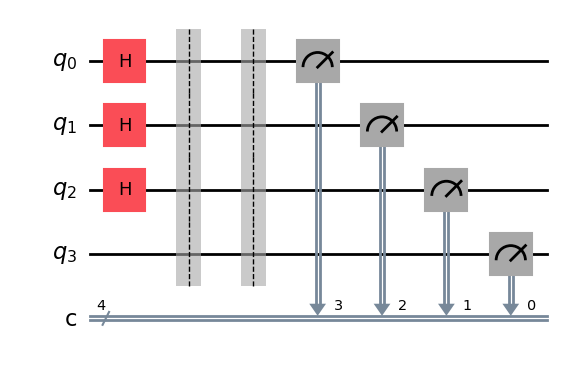

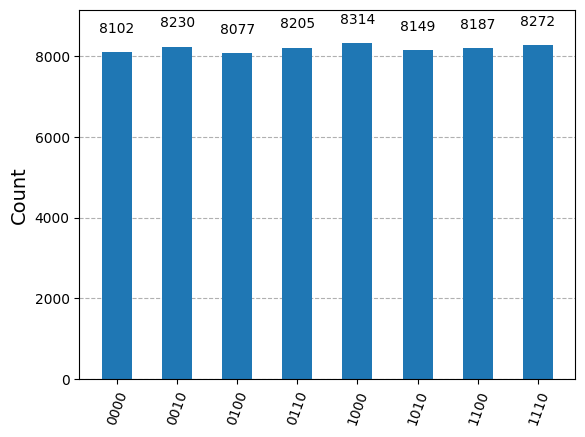

Incorrect circuit for vector  [1, 0, 1]


False

In [19]:
def testscal(s):
    k = len(s)
    def aux(*xs):
        y=xs[k]
        for i in range(k):
            if s[i] == 1:
                y ^= xs[i]
        return [*xs[:-1],y]
    return aux

check = True
for ss in ['101', '00', '001', '111', '10111']:
    s = list(map(int,ss))
    k = len(s)
    circ = circuitProduit(s)
    outset = classicset(k,1,testscal(s))
    check = validator(k, circ, outset)
    if not check:
        print('Incorrect circuit for vector ', s)
        break
check

## 3. More or fewer controls

Now that we have reviewed the constructions from the lecture, let's move on to controlled gates. In this part, we will revisit the constructions from the paper [*Elementary gates for quantum computation*](https://arxiv.org/abs/quant-ph/9503016) by A. Barenco *et al.* (*Phys. Rev. A* 52 (1995) 3457).

The question we study is the following: how can we efficiently simulate an $n$-controlled NOT gate $C^nX$? Efficiency will be measured by two criteria: the circuit depth and the number of ancillary qubits required.


### 3.1 Simulating $C^nX$ with $CCX$

We first consider Lemma 7.2 on page 18 of the Barenco *et al.* paper. It contains a figure that we reproduce here with Qiskit:


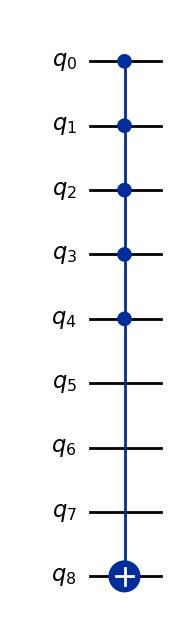

In [20]:
left = QuantumCircuit(9)
left.mcx([0,1,2,3,4],8)
draw_circ(left)


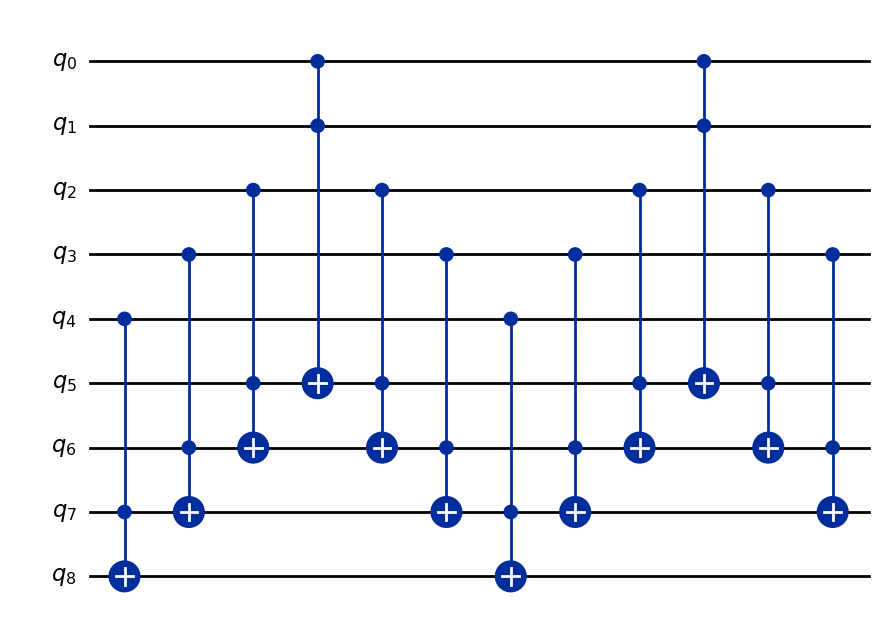

In [21]:
right = QuantumCircuit(9)
right.ccx(4,7,8)
right.ccx(3,6,7)
right.ccx(2,5,6)
right.ccx(0,1,5)
right.ccx(2,5,6)
right.ccx(3,6,7)
right.ccx(4,7,8)
right.ccx(3,6,7)
right.ccx(2,5,6)
right.ccx(0,1,5)
right.ccx(2,5,6)
right.ccx(3,6,7)
draw_circ(right)


Let's ask Qiskit to check whether these two circuits are equivalent.


In [22]:
Operator(left) == Operator(right)


True

In the text of the paper, the notation $\Lambda_n(\sigma_x)$ denotes $C^nX$. Write a function that takes as input a number $n$ of qubits and a number $m$ of control bits. This function must test whether the hypotheses are satisfied (if not, it returns `None`), build the circuits `left` and `right` accordingly, verify that `Operator(left) == Operator(right)`, and return `right`.


In [23]:
def first_sim_cnx(n, m):
    "Simule une porte C^m(X) sur un circuit de n qubits"
    pass

### 3.2 Simulating $C^nX$ with $CCX$ and a single ancilla

We now use Lemma 7.3 and Corollary 7.4 (pages 19–20) to use a single ancillary qubit. Here is the figure on page 20.


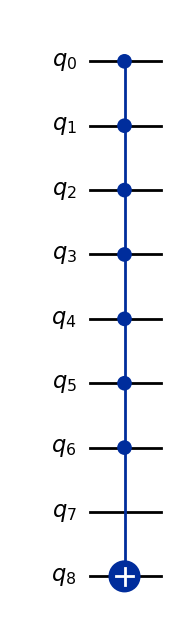

In [24]:
left = QuantumCircuit(9)
left.mcx([0,1,2,3,4,5,6],8)
draw_circ(left)


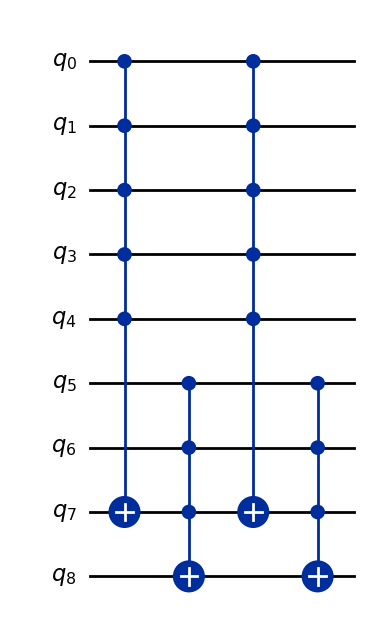

In [25]:
right = QuantumCircuit(9)
right.mcx([0,1,2,3,4],7)
right.mcx([5,6,7],8)
right.mcx([0,1,2,3,4],7)
right.mcx([5,6,7],8)
draw_circ(right)


In [26]:
Operator(left) == Operator(right)


True

Read and understand the assumptions of Lemma 7.3 and Corollary 7.4. Write a function that takes as input a number $n$ of qubits and a number $m$ of control bits. This function must test whether the assumptions are satisfied (if not, it returns `None`), build the corresponding circuits `left` and `right`, verify that `Operator(left) == Operator(right)`, and return `right`.


In [28]:
def second_sim_cnx(n, m):
    "Simulate a gate C^m(X) in an n qubits circuit using a single anciliary qubit"
    pass

### 3.3 Did you enjoy that? Want more? (BONUS)

With quantum gates, we can get rid of this last ancillary qubit and simulate the gate $C^nX$ directly. This is the subject of Lemmas 7.5 and 7.6 in the paper. For this we need the square-root-of-$X$ gate and its controlled versions. In Qiskit it is denoted `SX`.

Here is an example circuit that realises $CX$ thanks to this trick:


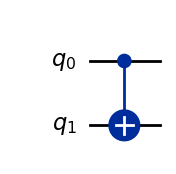

In [29]:
left = QuantumCircuit(2)
left.cx(0,1)
draw_circ(left)


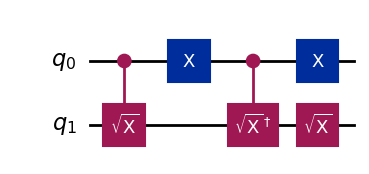

In [30]:
right = QuantumCircuit(2)
right.csx(0,1)
right.x(0)
right.csx(0,1).inverse()
right.x(0)
right.sx(1)
draw_circ(right)


In [31]:
Operator(left) == Operator(right)


True

If you need generalised controlled gates, you can build them like this (this is the example from the figure on page 21):


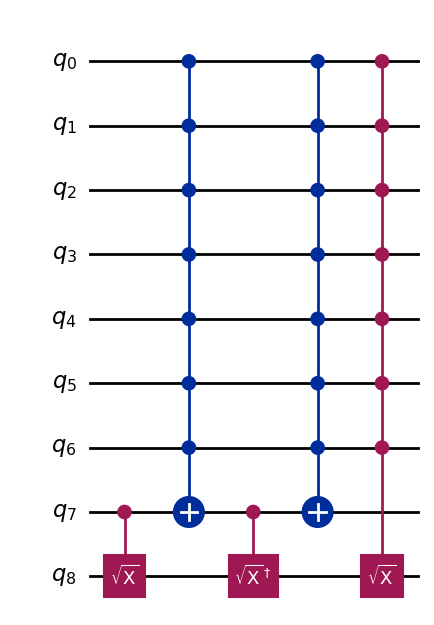

True

In [32]:
from qiskit.circuit.library.standard_gates import SXGate

right = QuantumCircuit(9)
right.csx(7,8)
right.mcx([0,1,2,3,4,5,6],7)
right.csx(7,8).inverse()
right.mcx([0,1,2,3,4,5,6],7)
right.append(SXGate().control(7), (0,1,2,3,4,5,6,8))
draw_circ(right)

left = QuantumCircuit(9)
left.mcx([0,1,2,3,4,5,6,7],8)
Operator(left) == Operator(right)


If you need to build higher-order roots of $X$, you can construct them like this:


In [33]:
def racine(circ, kieme, qubit):
    "simule une porte racine kieme sur le qubit du circuit circ"
    circ.h(0)
    circ.p(-pi/k, 0)
    circ.h(0)

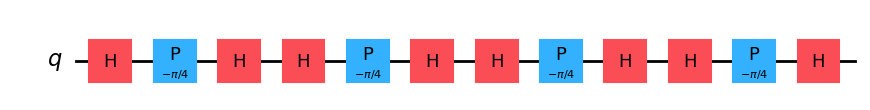

<IPython.core.display.Latex object>

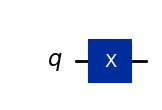

<IPython.core.display.Latex object>

True

In [34]:
from math import pi
mycirc = QuantumCircuit(1)
k = 1<<2
for _ in range(k):
    racine(mycirc, k, 0)
show(mycirc)
moncircuitb = QuantumCircuit(1)
moncircuitb.x(0)
show(moncircuitb)
Operator(mycirc) == Operator(moncircuitb)


Read and understand the assumptions of Lemma 7.5 and Corollary 7.6. Write a function that takes as input a number $n$ of qubits and a number $m$ of control bits. This function must test whether the assumptions are satisfied (if not, it returns `None`), build the circuits `left` and `right` accordingly, verify that `Operator(left) == Operator(right)`, and return `right`.


In [35]:
def last_sim_cnx(n):
    "Simule une porte C^n(X) sur un circuit de n qubits en utilisant X, SX, CSX et leurs inverses"
    pass

### 3.4 End of the worksheet! Still here? (BONUS of the BONUS)

In the tutorials you looked at building the $n$-OR gate (OR with $n$ inputs). Show that we can simulate this gate with $n+1$ qubits ($n$ inputs and 1 output), without any ancilla qubit, using $C^nX$ gates.


In [36]:
def nor_gate(n):
    "Construit un circuit à n+1 qubits qui simule n-OR avec des portes C^nX"
    pass

### 3.5 Time to leave the room… We're closing… (BONUS of the BONUS of the BONUS)

The reference paper for this part of the lab dates from 1995. Since then, several constructions have improved those results. If you want to implement these ideas more efficiently, we recommend two readings:
 - [Constructing Large Controlled Nots](https://algassert.com/ciqpus/2013/03/constructing-large-controlled-nots.html) — an intuitive explanation and a solid construction for simulation with a linear number of Toffoli gates;
 - [Polylogarithmic-depth controlled-NOT gates without ancilla qubits] — which proposes an even more efficient construction.
